# Gym4ReaL DamEnv: benchmark reproduction

We evaluate the four simple rules and supplied PPO checkpoint on **the authors' original 13 test years**. This is separate from our chronological MPC-versus-PPO experiment. We also trained one PPO from scratch with the source's fixed 200,000-step configuration.

Generate results with `uv run --group reproduction lake-como-reproduce`. Fresh-training results additionally require `lake-como-train-reference` and evaluating its final checkpoint with a separate output directory. No training or evaluation is run automatically by this notebook.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from lake_como.paths import PROJECT_ROOT

output = PROJECT_ROOT / 'results/reproduction'
assert (output / 'aggregate.csv').exists(), 'Run: uv run --group reproduction lake-como-reproduce'
metadata = json.loads((output / 'run.json').read_text())
print('Original test years:', metadata['years'])
print('Upstream commit:', metadata['upstream_commit'])
print('Checkpoint hash:', metadata['checkpoint_sha256'])
summary = pd.read_csv(output / 'aggregate.csv')
display(summary.round(2))

Original test years: [1950, 1970, 1996, 1961, 1994, 1971, 1966, 2009, 2010, 1952, 2007, 1998, 1974]
Upstream commit: 48f3f284e8ccd3bd8fd7b49b6273590ff706670d
Checkpoint hash: 5888199fc191faca221400dd73fb5e3c4103bd60f8e98257e35124c2896d6f80


,policy,mean_objective_return,median_objective_return,mean_full_return,mean_flood_days,mean_low_water_days,mean_deficit_million_m3
0,random,-37997.71,-36179.12,-44322.79,12.08,32.08,959.30
1,mean,-28838.41,-29982.64,-32505.21,7.54,46.08,547.27
2,max,-20492.94,-16728.28,-43370.03,0.00,46.15,506.43
3,ead,-25179.66,-21559.37,-25960.79,16.23,10.23,371.41
4,ppo,-15371.75,-14153.18,-16901.94,1.31,20.15,493.71


## Compare with Figure 1

The plotted objective includes only weighted deficit, flood, and low-water penalties. Full reward includes two additional penalties. The curve shows averages across years; the band follows the upstream notebook's pointwise formula and does not represent uncertainty across training seeds.

The ordering and scale are visually consistent with Figure 1, but the paper's figure does not supply exact numerical reference values for a tolerance-based reproduction check.

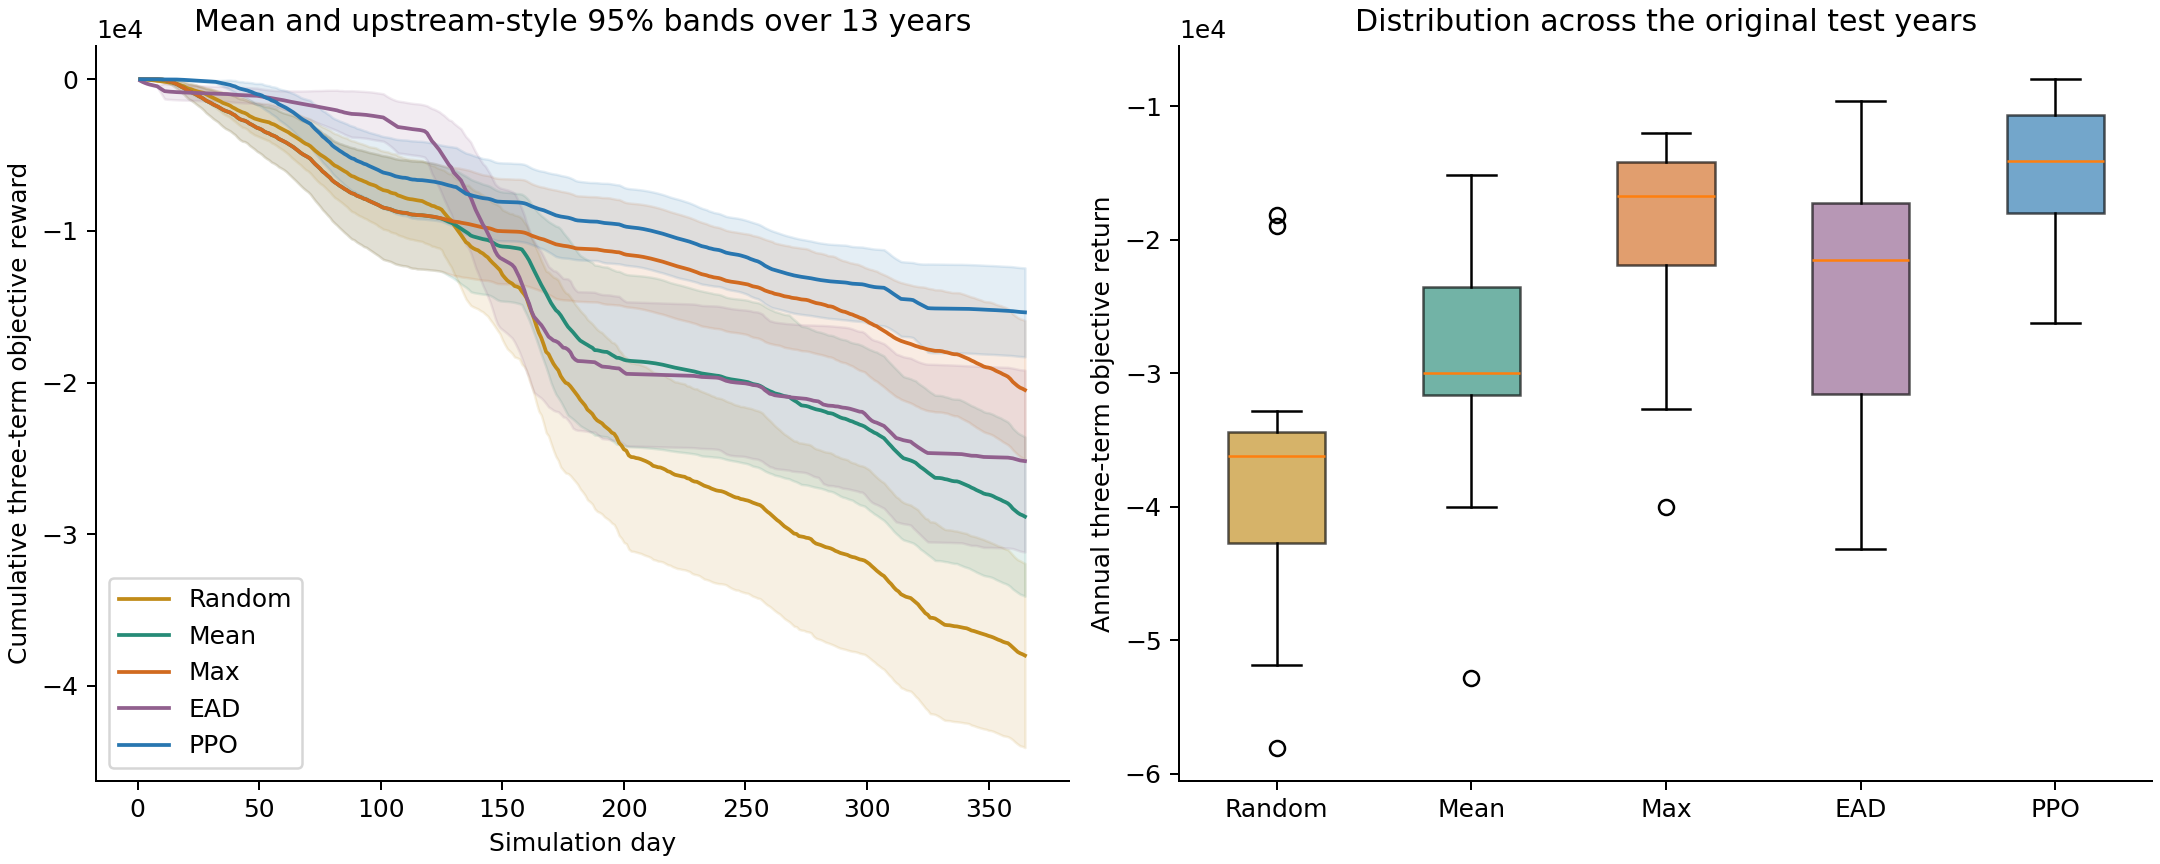

In [2]:
display(Image(filename=str(output / 'figure1_reproduction.png')))

## What the physical outcomes tell us

The strongest objective score does not mean the best value of every physical metric. Max avoids floods while allowing low water. EAD leaves less demand unmet than the supplied PPO. Examine those trade-offs alongside the aggregate reward.

In [3]:
annual = pd.read_csv(output / 'annual.csv')
display(annual.pivot(index='year', columns='policy', values='objective_return').round(1))
assert len(annual) == 65
assert annual.groupby('policy').size().eq(13).all()
assert annual.max_balance_error_m3.max() < 1e-4

policy,ead,max,mean,ppo,random
year,,,,,
1950,-20929.5,-32669.7,-52868.4,-18165.3,-58044.4
1952,-29303.5,-29869.7,-31612.8,-24501.4,-51424.5
1961,-17783.0,-13383.5,-32997.0,-10698.2,-36179.1
1966,-31598.2,-15181.4,-23582.8,-17780.6,-32832.6
1970,-17265.6,-16728.3,-16784.1,-14153.2,-18971.3
1971,-42775.0,-21305.9,-29982.6,-10461.2,-39817.1
1974,-11776.1,-15144.5,-15141.8,-7972.6,-18127.3
1994,-21559.4,-12196.9,-19714.1,-10357.4,-42710.1
1996,-40581.5,-21873.3,-30560.4,-26239.7,-34491.4


## One fresh training run

This uses the authors' original function and fixed configuration, seed 123, CPU, and one thread. Its final 200,000-step checkpoint is evaluated without choosing a checkpoint by test score. It is a training reproducibility check, not a new algorithm or a multiple-seed result.

,policy,mean_objective_return,median_objective_return,mean_full_return,mean_flood_days,mean_low_water_days,mean_deficit_million_m3,run
4,ppo,-15371.75,-14153.18,-16901.94,1.31,20.15,493.71,Supplied checkpoint
4,ppo,-12394.26,-11737.51,-14271.36,0.15,10.08,557.52,Fresh CPU run


Training elapsed seconds: 96.83


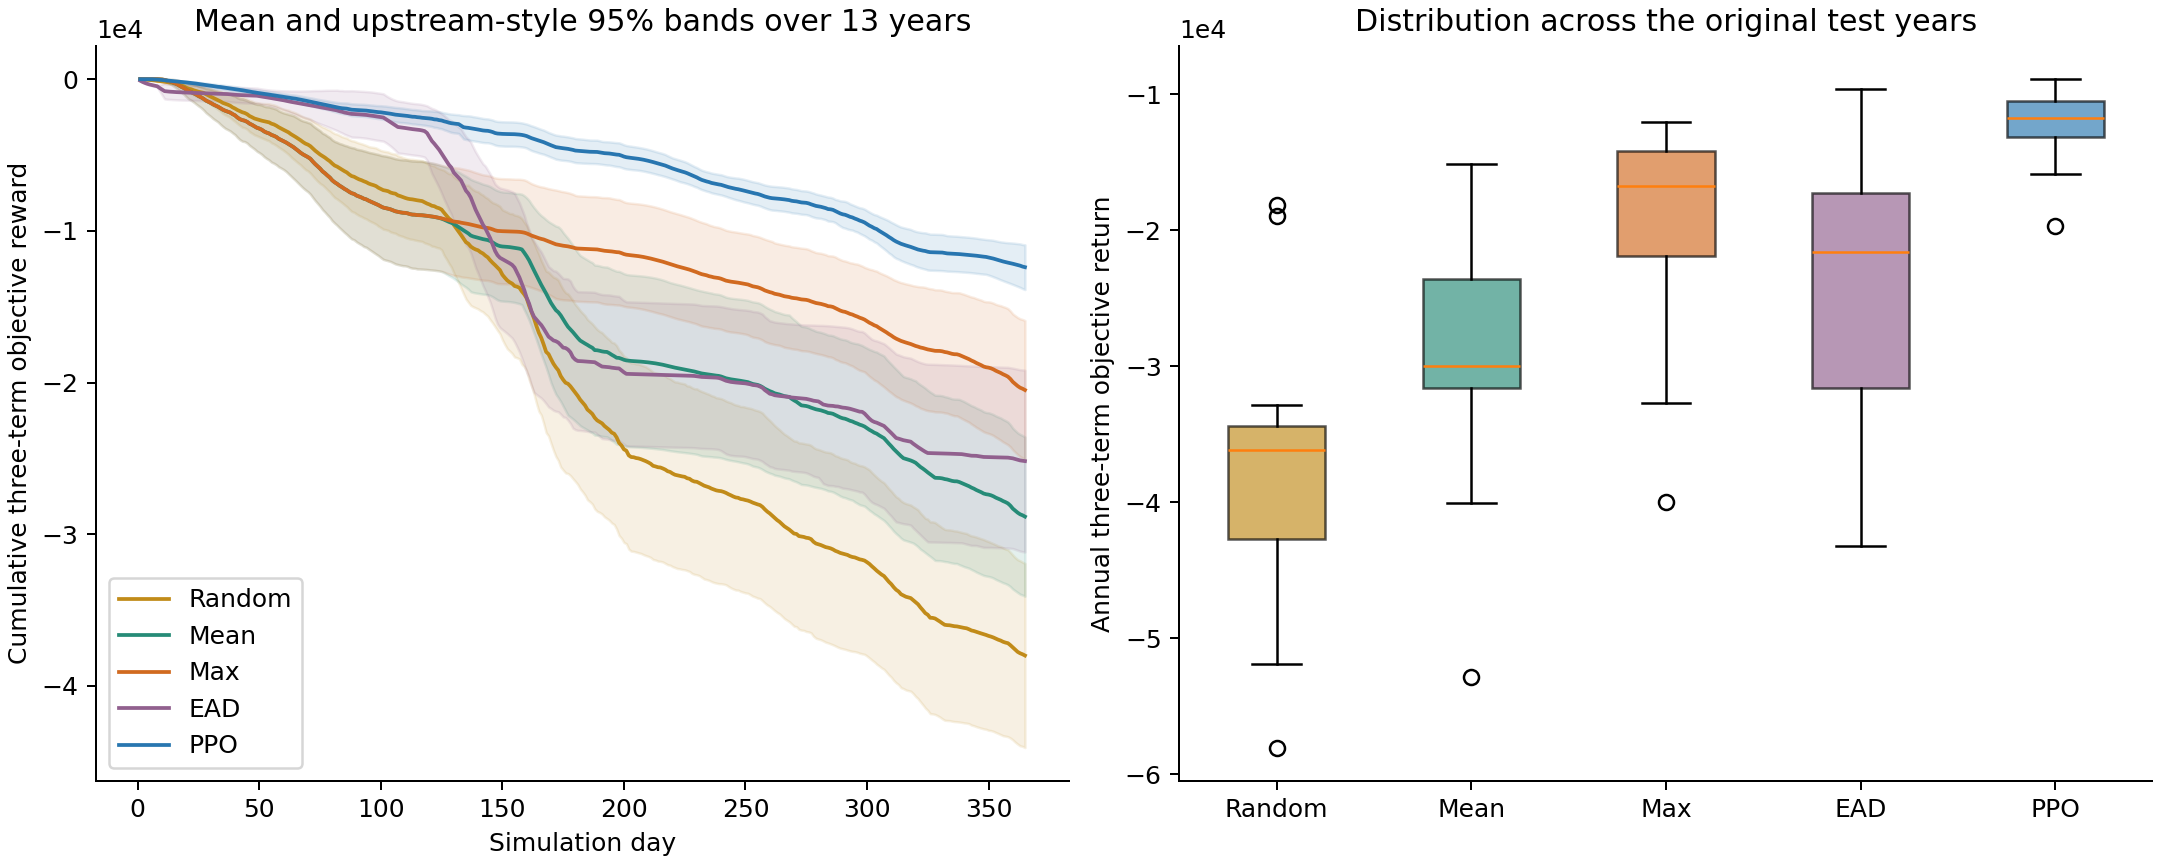

In [4]:
fresh = output / 'retrained/aggregate.csv'
if fresh.exists():
    comparison = pd.concat([
        summary.assign(run='Supplied checkpoint'),
        pd.read_csv(fresh).assign(run='Fresh CPU run')
    ])
    display(comparison[comparison.policy == 'ppo'].round(2))
    training = json.loads((output / 'training/training_run.json').read_text())
    print('Training elapsed seconds:', round(training['elapsed_seconds'], 2))
    display(Image(filename=str(output / 'retrained/figure1_reproduction.png')))
else:
    print('Fresh training has not been run in this checkout.')

## Limits of this reproduction

Inference uses saved frozen normalization and deterministic mean actions on CPU in FP32. The source agent's mixed-precision context and GPU arithmetic may differ. The random baseline has an explicit seed while the upstream notebook does not explicitly seed its action space. Independent tests check FP32 inference equivalence and reward accounting.

Both PPO models used original training years that overlap our chronological test years. Retrain on the chronological training split before the main engineering-versus-learning comparison. The corrected terminal observation used elsewhere in our project is deliberately disabled for these source-reproduction runs.

## Five training seeds

We retain the original seed 123 and add learner seeds 124–127 with the same fixed configuration and final 200,000-step checkpoint rule. Hydrological training-year sampling remains fixed at environment seed 123, so this isolates learner RNG variation; it does not test every source of randomness.

Each seed is evaluated on the same 13 original test years. Compute uncertainty across the **five seed means**, not by treating the 65 seed/year combinations as independent experiments. The supplied checkpoint is a separate reference, not a sixth newly trained seed.

,training_seed,objective_return,full_return,flood_days,low_water_days,deficit_million_m3,training_seconds
0,123,-12394.26,-14271.36,0.15,10.08,557.52,96.83
1,124,-20492.95,-28233.06,0.00,46.15,506.43,97.44
2,125,-18671.83,-20533.76,1.00,34.85,503.52,99.65
3,126,-20337.78,-23904.72,0.00,45.46,507.70,95.45
4,127,-21375.27,-24870.33,1.00,45.23,511.29,97.05


,Unnamed: 0,mean,std,min,max
0,objective_return,-18654.42,3633.42,-21375.27,-12394.26
1,full_return,-22362.65,5290.13,-28233.06,-14271.36
2,flood_days,0.43,0.52,0.00,1.00
3,low_water_days,36.35,15.42,10.08,46.15
4,deficit_million_m3,517.29,22.66,503.52,557.52


,training_seed,baseline,mean_objective_advantage,years_with_higher_objective,total_years
0,123,ead,12785.40,12,13
1,123,max,8098.68,13,13
2,123,mean,16444.16,13,13
3,123,random,25603.45,13,13
4,124,ead,4686.71,8,13
5,124,max,-0.01,2,13
6,124,mean,8345.47,12,13
7,124,random,17504.76,12,13
8,125,ead,6507.83,8,13
9,125,max,1821.11,10,13


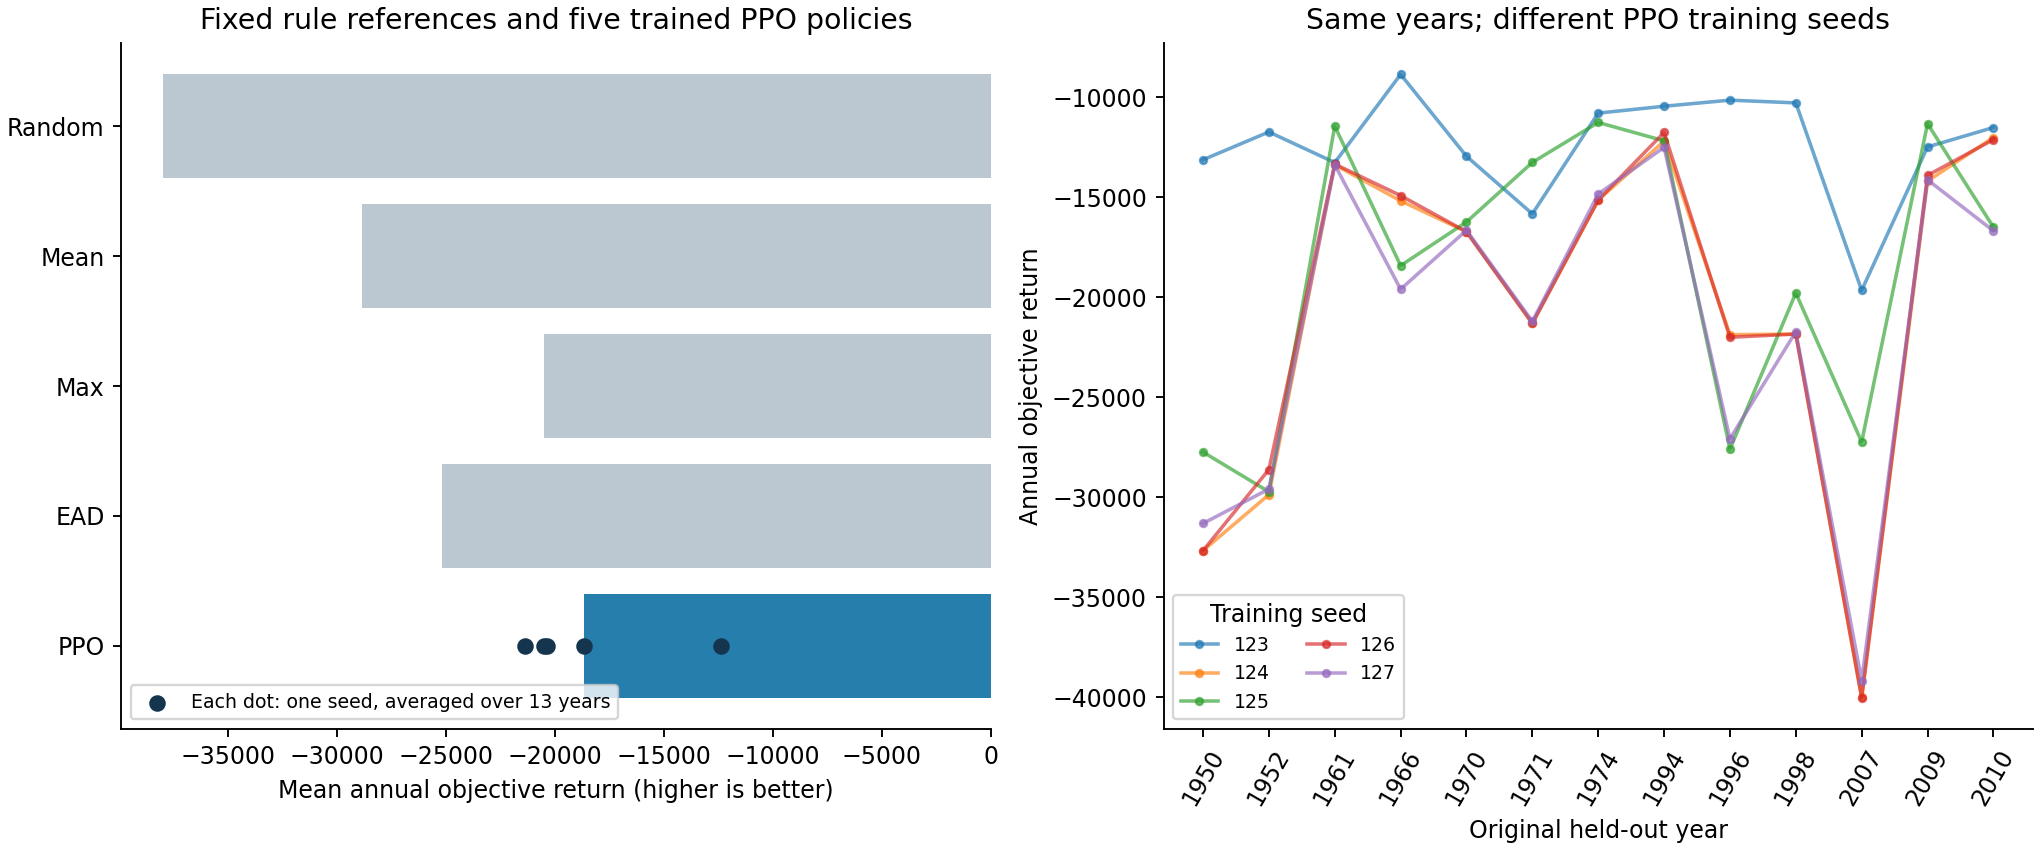

In [5]:
study = output / 'seeds'
if (study / 'aggregate_across_seeds.csv').exists():
    seed_means = pd.read_csv(study / 'seed_means.csv')
    seed_variation = pd.read_csv(study / 'aggregate_across_seeds.csv')
    paired = pd.read_csv(study / 'paired_comparisons.csv')
    display(seed_means.round(2))
    display(seed_variation.round(2))
    display(paired.round(2))
    display(Image(filename=str(study / 'seed_study.png')))
else:
    print('Run: uv run --group reproduction lake-como-seed-study --workers 2')

### Interpretation of the seed check

The five policy means average **−18,654 ± 3,633** (sample SD). Seed 123 was favorable, rather than representative of every run. Compared with Max, three seeds have a higher mean objective, one is effectively tied, and one has a lower mean objective. Five seeds and these fixed test years do not establish a universal advantage. Keep the physical metrics and both sources of variation—training seed and hydrological year—visible.